### 1. Carga de datos
Leemos el archivo JSON para contar los satélites totales, obtener la fecha media de los datos y calcular cuántos se descartan por tener una altitud menor a 100 km.

In [4]:
from catalogo import leer_satelites
from satelite import crear_satelites
from datetime import datetime, timezone
from funciones_base import epoch_medio
satelites= leer_satelites("datos/satelites.json")
fecha= epoch_medio(satelites)
ahora= datetime.now(timezone.utc)
transcurridos= ahora - fecha
orbitando= crear_satelites(satelites, ahora)
total1= len(satelites)
total2= len(orbitando)
descartados= total1 - total2
print(f"La fecha de los satelites son {fecha}")
print(f"Los días transcurridos entre que se imprimio hasta hoy son {transcurridos}")
print(f"El archivo tiene {total1} satelites")
print(f"Hay {descartados} satelites descartados")

La fecha de los satelites son 2026-10-14 06:30:18.482258+00:00
Los días transcurridos entre que se imprimio hasta hoy son 35 days, 15:01:16.066099
El archivo tiene 16710 satelites
Hay 125 satelites descartados


### 2. Grupos
Agrupamiento de los satélites según su nombre para saber a qué grupo pertenecen, y cálculo de qué porcentaje del total son de Starlink.

In [5]:
from catalogo import contar_por_grupo
conteo= contar_por_grupo(satelites)
starlink= conteo.get("Starlink", 0)
porcentaje= (starlink/total1)*100
print(f"Hay {porcentaje}% satelites de Starlink entre el total")


Hay 66.5769000598444% satelites de Starlink entre el total


### 3. Lanzamientos por año
Conteo de la cantidad de satélites (actualmente activos) que fueron lanzados en cada año desde 2015, identificando el año con el mayor número de lanzamientos.

In [6]:
from catalogo import lanzamientos_por_anio
datos_lanzamientos= lanzamientos_por_anio(satelites)
for anios in sorted(datos_lanzamientos.keys()):
    print(f"En el año {anios} se lanzaron {datos_lanzamientos[anios]} satelites")
anio_top= max(datos_lanzamientos, key=datos_lanzamientos.get)
print(f"El año en que hubo más lanzamientos fue en el año {anio_top} con {datos_lanzamientos[anio_top]} lanzamientos")


En el año 1964 se lanzaron 2 satelites
En el año 1965 se lanzaron 3 satelites
En el año 1967 se lanzaron 4 satelites
En el año 1971 se lanzaron 1 satelites
En el año 1974 se lanzaron 1 satelites
En el año 1975 se lanzaron 1 satelites
En el año 1976 se lanzaron 1 satelites
En el año 1983 se lanzaron 1 satelites
En el año 1984 se lanzaron 1 satelites
En el año 1986 se lanzaron 1 satelites
En el año 1988 se lanzaron 1 satelites
En el año 1989 se lanzaron 3 satelites
En el año 1990 se lanzaron 2 satelites
En el año 1991 se lanzaron 1 satelites
En el año 1992 se lanzaron 1 satelites
En el año 1993 se lanzaron 6 satelites
En el año 1994 se lanzaron 1 satelites
En el año 1995 se lanzaron 3 satelites
En el año 1996 se lanzaron 6 satelites
En el año 1997 se lanzaron 4 satelites
En el año 1998 se lanzaron 25 satelites
En el año 1999 se lanzaron 8 satelites
En el año 2000 se lanzaron 10 satelites
En el año 2001 se lanzaron 11 satelites
En el año 2002 se lanzaron 13 satelites
En el año 2003 se lan

### 4. Tipos de órbita
Clasificación y conteo de los satélites según su altitud en órbitas LEO, MEO, GEO y HEO.

In [7]:
from analisis import contar_por_tipo
orbitas= contar_por_tipo(orbitando)
print(orbitas)

{'LEO': 15776, 'MEO': 203, 'GEO': 585, 'HEO': 21}


### 5. Extremos
Identificación de los satélites con mayor y menor altitud, incluyendo un listado con el top 10 de cada extremo.

In [8]:
from analisis import mas_bajo, mas_alto, ordenar_por
bajito= mas_bajo(orbitando)
altito= mas_alto(orbitando)
top10bajo= ordenar_por(orbitando, "altitud_km", descendente= False)[:10]
for topbajo in top10bajo: 
    print(topbajo)
top10alto = ordenar_por(orbitando, "altitud_km", descendente= True)[:10]
for topalto in top10alto:
    print(topalto)
print(f"El satelite más bajo es: {bajito}")
print(f"El satelite más alto es: {altito}")


STARLINK-1420 | LEO | 107.7 km
STARLINK-36253 | LEO | 118.0 km
STARLINK-40093 | LEO | 124.8 km
STARLINK-40084 | LEO | 128.8 km
STARLINK-30239 | LEO | 133.8 km
STARLINK-4394 | LEO | 136.0 km
STARLINK-3620 | LEO | 139.1 km
STARLINK-1327 | LEO | 142.2 km
2024-125A | LEO | 143.8 km
STARLINK-32664 | LEO | 160.6 km
TESS | HEO | 192624.3 km
MMS 4 | HEO | 145977.9 km
MMS 1 | HEO | 145931.7 km
MMS 3 | HEO | 145929.7 km
MMS 2 | HEO | 145916.8 km
SMILE | HEO | 85970.4 km
THEMIS D | HEO | 77740.0 km
ASTRANIS UTILITYSAT | HEO | 61099.4 km
THEMIS E | HEO | 55475.5 km
POLAR | HEO | 47785.8 km
El satelite más bajo es: STARLINK-1420 | LEO | 107.7 km
El satelite más alto es: TESS | HEO | 192624.3 km


### 6. Comparación de grupos
Tabla resumen con las estadísticas de altitud (mínima, máxima y promedio) y la cantidad total de satélites para cada grupo.

In [9]:
from analisis import resumen_por_grupo

resumen = resumen_por_grupo(orbitando)

print(f"{'Grupo':<10} | {'cantidad':<10} | {'min':<15} | {'max':<15} | {'promedio':<15}")
print("-" * 75)

for grupo, valores in resumen.items():
    print(f"{grupo:<10} | {valores['cantidad']:<10} | {valores['min']:<15} | {valores['max']:<15} | {valores['promedio']:<15}")

Grupo      | cantidad   | min             | max             | promedio       
---------------------------------------------------------------------------
Otros      | 4059       | 143.84          | 192624.3        | 6404.77        
GPS        | 40         | 19746.82        | 21034.46        | 20252.21       
Globalstar | 36         | 688.04          | 1829.59         | 1293.52        
BeiDou     | 55         | 21504.97        | 36025.24        | 27221.75       
Iridium    | 80         | 633.29          | 805.95          | 777.72         
OneWeb     | 651        | 530.27          | 1251.11         | 1210.01        
Starlink   | 11023      | 107.74          | 596.69          | 465.81         
Qianfan    | 252        | 414.99          | 1108.79         | 1033.41        
Kuiper     | 389        | 434.23          | 656.06          | 632.02         


### 7. Bariloche
Filtrado de los satélites que se encuentran sobre la zona geográfica de Bariloche en el instante actual, presentados en orden ascendente según su altitud.

In [10]:
from analisis import en_zona ,ordenar_por

    
BARILOCHE = (-76.30, -46.13, -66.30, -36.13)   # lon_min, lat_min, lon_max, lat_max


satelites_bariloche = en_zona(orbitando, BARILOCHE)
print(f"Hay {len(satelites_bariloche)} satélites sobre la zona de Bariloche")


ordenados = ordenar_por(satelites_bariloche, "altitud_km")

for sat in ordenados:
    print(sat)

Hay 37 satélites sobre la zona de Bariloche
STARLINK-11185 [DTC] | LEO | 306.1 km
STARLINK-11428 [DTC] | LEO | 311.1 km
STARLINK-11680 [DTC] | LEO | 327.1 km
STARLINK-11179 [DTC] | LEO | 364.5 km
STARLINK-11163 [DTC] | LEO | 371.1 km
STARLINK-11123 [DTC] | LEO | 372.4 km
STARLINK-34429 | LEO | 470.0 km
STARLINK-35800 | LEO | 470.6 km
STARLINK-37756 | LEO | 472.3 km
STARLINK-4159 | LEO | 472.9 km
STARLINK-35452 | LEO | 474.2 km
STARLINK-35398 | LEO | 474.7 km
STARLINK-3735 | LEO | 475.1 km
STARLINK-4116 | LEO | 475.4 km
STARLINK-4100 | LEO | 475.8 km
STARLINK-31609 | LEO | 476.9 km
STARLINK-2683 | LEO | 477.9 km
STARLINK-4095 | LEO | 479.2 km
STARLINK-4345 | LEO | 480.3 km
STARLINK-2161 | LEO | 481.8 km
STARLINK-32443 | LEO | 481.9 km
STARLINK-4341 | LEO | 482.7 km
STARLINK-3339 | LEO | 484.3 km
STARLINK-2523 | LEO | 485.5 km
STARLINK-33832 | LEO | 489.2 km
STARLINK-33671 | LEO | 491.0 km
STARLINK-33844 | LEO | 491.7 km
STARLINK-35977 | LEO | 491.9 km
STARLINK-33712 | LEO | 492.2 km
STA

### 8. Conclusiones
En el análisis del catálogo se observa que el grupo predominante es **[Starlink]**. El año con mayor cantidad de satélites lanzados (que siguen activos) fue **[ 2025 con 4289]**. En cuanto a la distribución, la mayoría corresponde a órbitas de tipo **[LEO]**. Finalmente, sobre la zona de Bariloche, detectamos un total de **[40]** satélites en el instante calculado.

### Etapa 2


### 1. Lanzamientos en el tiempo
Gráfico de barras con lo que devuelve lanzamientos_por_anio (eje X año, eje Y cantidad de satélites lanzados).

Recibe dos diccionarios {año: cantidad} y dibuja barras apiladas, con leyenda. Los años que falten en uno de los diccionarios cuentan como 0. Sirve, por ejemplo, para comparar Starlink con el resto.

Consigna: 
Lanzamientos por año: barras por año y barras apiladas Starlink vs. resto, de 1990 a 2026. ¿Desde qué año cambia la escala? ¿Qué parte de ese cambio explica Starlink?

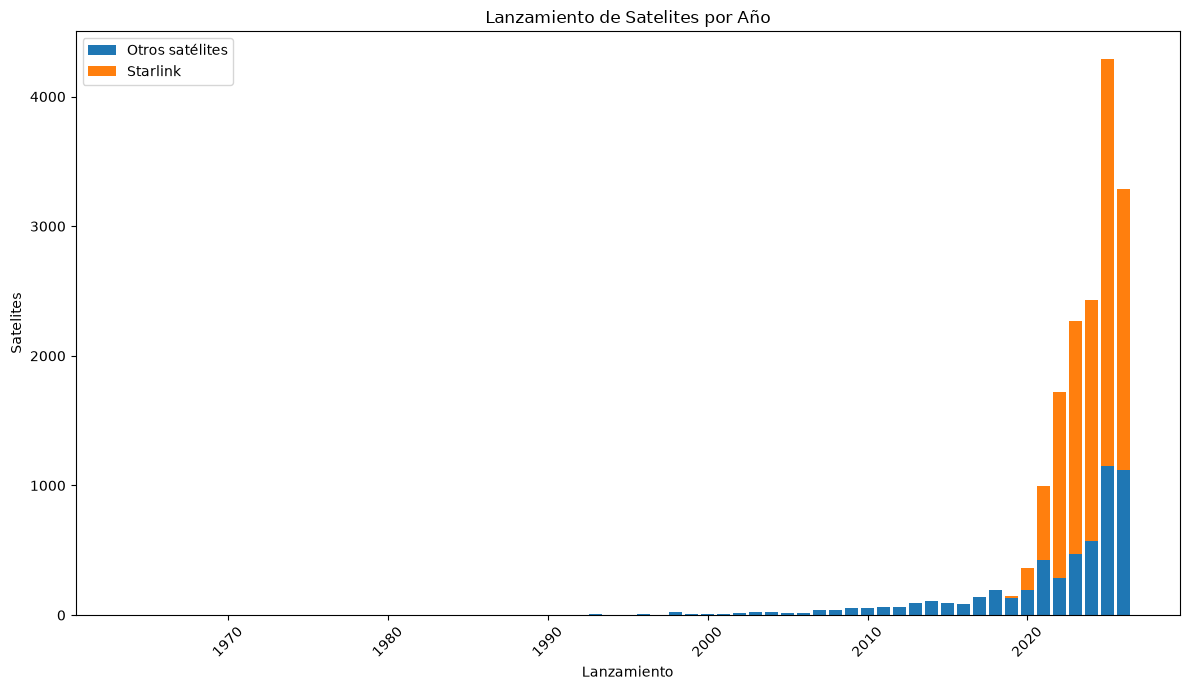

In [11]:
import matplotlib.pyplot as plt
from catalogo import grupo, anio_lanzamiento, leer_satelites
satelites= leer_satelites("datos/satelites.json")
starlink= {}
resto= {}
for registro in satelites: 
    nombre= registro.get("OBJECT_NAME", "")
    anio = anio_lanzamiento(registro)
    if grupo(nombre) == "Starlink":
        starlink[anio] = starlink.get(anio, 0) + 1
    else:
        resto[anio] = resto.get(anio, 0) + 1
anios= sorted(list(set(starlink.keys()).union(set(resto.keys()))))
cantidad_starlink= [starlink.get(anio, 0) for anio in anios]  
cantidad_resto= [resto.get(anio, 0) for anio in anios]
plt.figure(figsize=(12, 7))
plt.bar(anios, cantidad_resto, label="Otros satélites")
plt.bar(anios, cantidad_starlink, bottom=cantidad_resto, label="Starlink")
plt.xlabel("Lanzamiento")
plt.ylabel("Satelites")
plt.title("Lanzamiento de Satelites por Año")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Se puede opbservar que a partir del año 2020 para adelante empieza un cambio en la escala de lanzamientos de satelites.

Más de la mitad de los lanzamientos son de parte de la empreza **Starlink**.

### 2. Grupos 
 Altura media por grupo 
 
 Pregunta: ¿qué grupos están en órbita baja y cuáles más arriba?

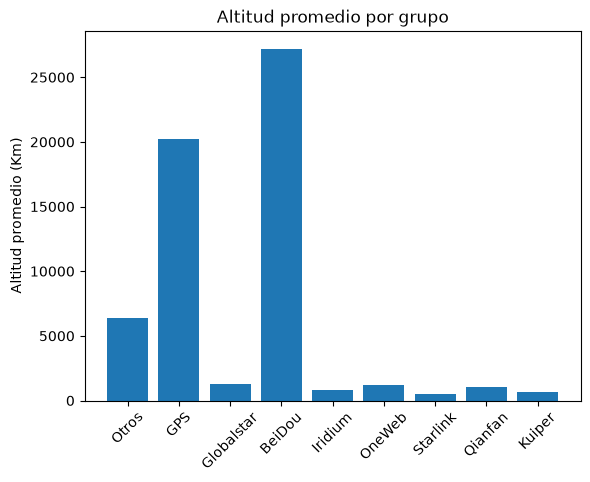

In [12]:
#Etapa2
import matplotlib.pyplot as plt
from analisis import resumen_por_grupo

def grafico_altitud_por_grupo(resumen:dict):

    grupo = []
    altiudes = []
    for nombre_grupo, datos in resumen.items():
        grupo.append(nombre_grupo)
        altiudes.append(datos["promedio"])

    plt.bar(grupo, altiudes)
    plt.ylabel("Altitud promedio (Km)")
    plt.xticks(rotation=45)
    plt.title("Altitud promedio por grupo")
    plt.show()


resumen = resumen_por_grupo(orbitando)
grafico_altitud_por_grupo(resumen)

Los grupos que más arriba están son BeiDou, GPS y Otros... 
mientras que los demas satelites estan en orbita baja


### .3 Altitudes en órbita baja:
histograma de las altitudes entre 200 y 2.000 km, con bins de ancho_bin km. 

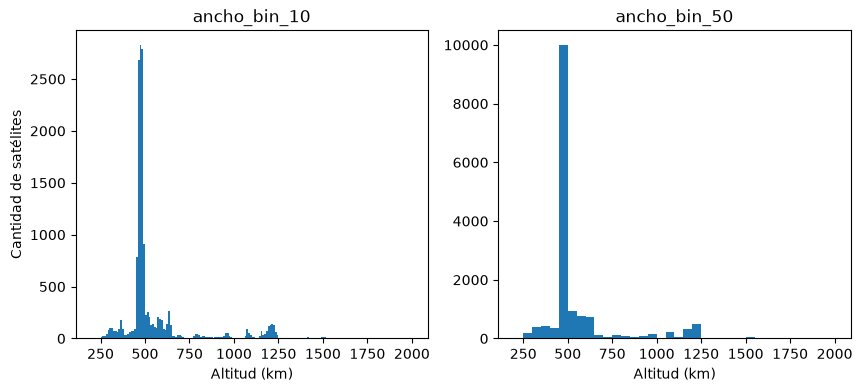

In [13]:
import numpy as np
# Pista: np.logspace y plt.xscale("log").

mi_lista = []
for satelite in orbitando:
    if 2000 >= satelite.altitud_km >= 200:
        mi_lista.append(satelite.altitud_km)

bins_10 = np.arange(200, 2000 + 10, 10)
bins_50 = np.arange(200, 2000 + 50, 50)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))  # dos Axes, uno al lado del otro
ax1.set_xlabel("Altitud (km)")
ax1.set_ylabel("Cantidad de satélites")

ax1.hist(mi_lista, bins_10)
ax1.set_title("ancho_bin_10")

ax2.hist(mi_lista,  bins_50)
ax2.set_title("ancho_bin_50")
ax2.set_xlabel("Altitud (km)")

plt.show()




Consigna: con ancho_bin=10 y con ancho_bin=50. ¿Qué se ve con uno que no se ve con el otro? ¿A qué alturas se concentran los satélites?

En ancho_bin=10 solo llega hasta **2500** satelites mientras que en ancho_bin=50
llega a los **10.000**.

Los satelites se concentran entre los **400** y **500** km aprox

### .3 Todas las altitudes:
histograma de todas las altitudes con el eje X en escala logarítmica y bins de ancho logarítmico.

Consigna: Identifiquen los picos y relaciónenlos con los tipos de órbita (LEO, MEO, GEO).

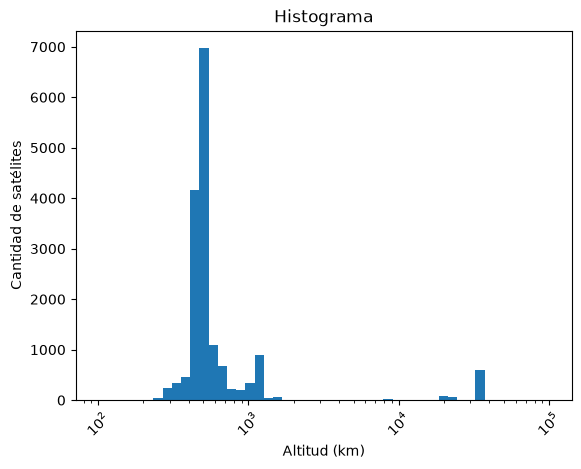

In [14]:
mis_altitudes = [x.altitud_km for x in orbitando]

bins_log =np.logspace(2, 5, 50)

plt.ylabel("Cantidad de satélites")
plt.xlabel("Altitud (km)")

plt.xticks(rotation=45)
plt.title("Histograma")

plt.hist(mis_altitudes, bins=bins_log)
plt.xscale("log")
plt.show()

Preponderan los satelites tipo **LEO** que son de baja orbita(menor a 2.000 km), mientras que los tipo **MEO** de orbita media son muy pocos y los de orbita tipo **GEO** aparece un pico aislado. 

### 4. Inclinaciones

Pregunta: ¿qué inclinaciones se repiten más? Filtren por grupo (por ejemplo Starlink y GPS) y vean a qué grupo corresponde cada pico.


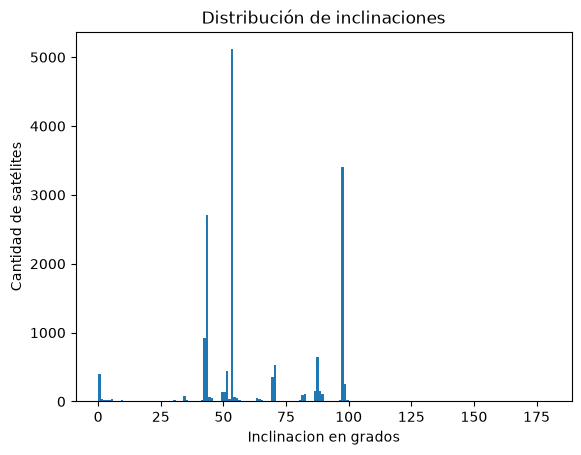

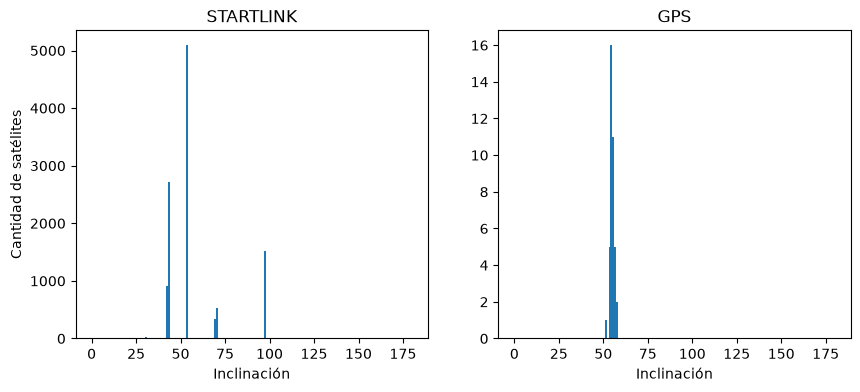

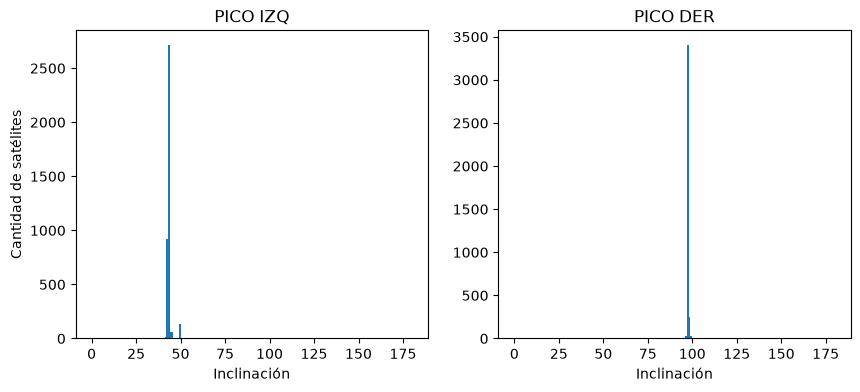

Grupo de pico aislado izquierda: {'Otros': 307, 'BeiDou': 4, 'Starlink': 3613}
Grupo de pico aislado derecha: {'Otros': 2216, 'Starlink': 1523}


In [15]:
inclinaciones = [float(dato["INCLINATION"]) for dato in satelites if "INCLINATION" in dato]

plt.xlabel("Inclinacion en grados")
plt.ylabel("Cantidad de satélites") 
plt.title("Distribución de inclinaciones")
mi_bins=np.arange(0, 181, 1)
plt.hist(inclinaciones, mi_bins)
plt.show() 

#Creando el grafico
grafico_starlink_datos = [float(dato["INCLINATION"]) for dato in satelites if "INCLINATION" in dato and "STARLINK" in dato["OBJECT_NAME"]]
grafico_gps_datos = [float(dato["INCLINATION"]) for dato in satelites if "INCLINATION" in dato and "NAVSTAR" in dato["OBJECT_NAME"]]


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))  # dos Axes, uno al lado del otro
ax1.set_xlabel("Inclinación")
ax1.set_ylabel("Cantidad de satélites")
ax1.set_title("STARTLINK")
ax1.hist(grafico_starlink_datos, mi_bins)


ax2.set_title("GPS")
ax2.set_xlabel("Inclinación")
ax2.hist(grafico_gps_datos, mi_bins)
plt.show()

#Graficando los picos aislados
grupo_pico_aislado_der = [dato["OBJECT_NAME"] for dato in satelites if "INCLINATION" in dato and float(dato["INCLINATION"]) >= 90]
grafico_pico_aislado_der_datos = [float(dato["INCLINATION"]) for dato in satelites if "INCLINATION" in dato and float(dato["INCLINATION"]) >= 90]

grupo_pico_aislado_izq = [dato["OBJECT_NAME"] for dato in satelites if "INCLINATION" in dato and 50 >= float(dato["INCLINATION"]) >= 40 ]
grafico_pico_aislado_izq_datos = [float(dato["INCLINATION"]) for dato in satelites if "INCLINATION" in dato and 50 >= float(dato["INCLINATION"]) >= 40]


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4)) 
ax1.set_xlabel("Inclinación")
ax1.set_ylabel("Cantidad de satélites")
ax1.set_title("PICO IZQ")
ax1.hist(grafico_pico_aislado_izq_datos, mi_bins)


ax2.set_title("PICO DER")
ax2.set_xlabel("Inclinación")
ax2.hist(grafico_pico_aislado_der_datos, mi_bins)
plt.show()



#De que grupo son los picos aislados?
def ver_picos_grupo(lista:list)-> dict:

    mi_dicc= {}
    for sat in lista:

        nombre_grupo = grupo(sat)
        if nombre_grupo not in mi_dicc:
            mi_dicc[nombre_grupo] = 1
        else:
            mi_dicc[nombre_grupo] += 1
    return mi_dicc

print(f"Grupo de pico aislado izquierda: {ver_picos_grupo(grupo_pico_aislado_izq)}")
print(f"Grupo de pico aislado derecha: {ver_picos_grupo(grupo_pico_aislado_der )}")



El pico más grande le corresponde a **Starlink**, aproximadamente entre 50° y 55° grados.

Los picos asilado de la izquierda (entre 40° y 50°), y el de la derecha (entre 90° y 100° grados), corresponde a **otro** tipo de empresas y a **Starlink**.


### TEMA LIBRE

¿En qué franjas de latitud y longitud del planeta se concentra la mayor densidad de satélites activos MEO y GEO en un instante dado?

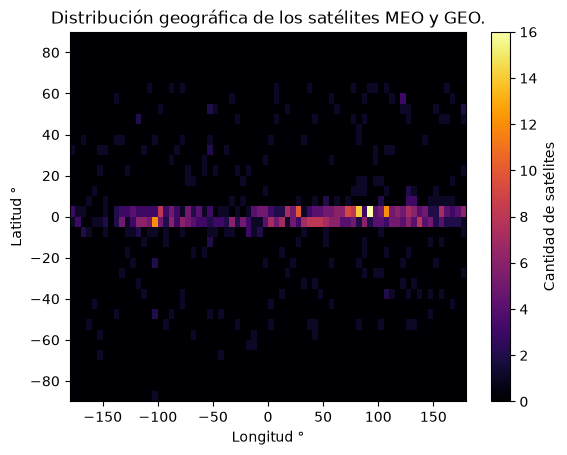

In [16]:
import matplotlib.pyplot as plt 


def mapa_calor_orbitas_altas(satelites):

    """Genera un mapa de calor con la distribución geográfica (longitud y latitud) 
    de los satélites de órbita MEO y GEO."""
    longitud= [] 
    latitud= []

    for x in satelites:
        if x.tipo_orbita() in ["MEO", "GEO", ]:
            longitud.append(x.longitud)
            latitud.append(x.latitud)

    plt.hist2d(longitud, latitud, bins=[72, 36], cmap="inferno", range=[[-180, 180], [-90, 90]])
    plt.colorbar(label="Cantidad de satélites")
    plt.xlabel("Longitud °")
    plt.ylabel("Latitud °")
    plt.title("Distribución geográfica de los satélites MEO y GEO.")
    plt.show()

mapa_calor_orbitas_altas(orbitando)




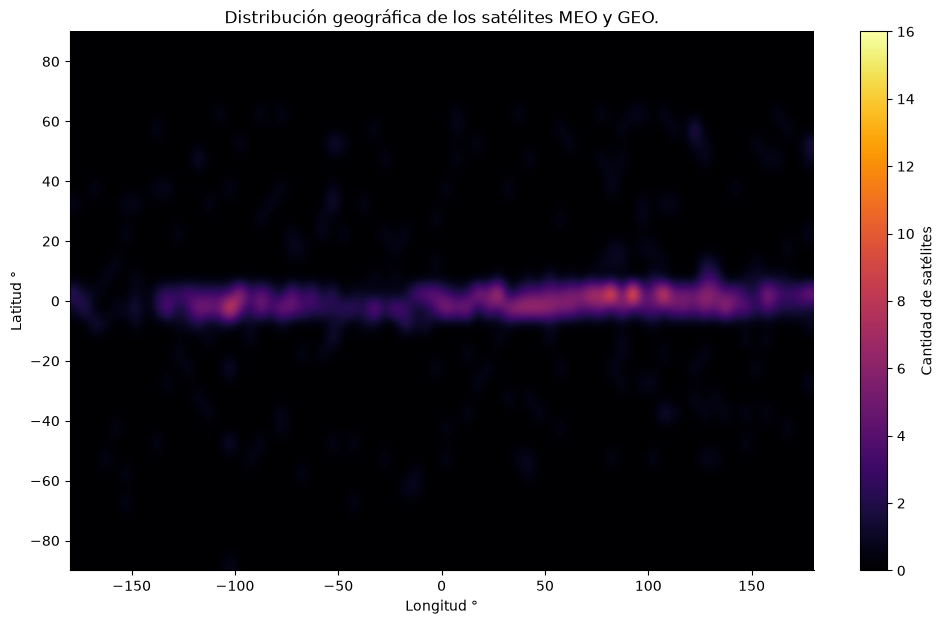

In [27]:
import matplotlib.pyplot as plt 
import numpy as np

def mapa_calor_orbitas_altas(satelites):

    """Genera un mapa de calor con la distribución geográfica (longitud y latitud) 
    de los satélites de órbita MEO y GEO."""
    longitud= [] 
    latitud= []

    for x in satelites:
        if x.tipo_orbita() in ["MEO", "GEO", ]:
            longitud.append(x.longitud)
            latitud.append(x.latitud)
    longitud= np.array(longitud)
    latitud= np.array(latitud)
    hist, xedges, yedges = np.histogram2d(longitud, latitud, bins= [72, 36], range=[[-180, 180], [-90, 90]])
       
    plt.figure(figsize=(12, 7))
    plt.imshow(hist.T, extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]], origin='lower', cmap="inferno", aspect='auto', interpolation= "bicubic")
    cbar= plt.colorbar()
    cbar.set_label("Cantidad de satélites")
    plt.xlabel("Longitud °")
    plt.ylabel("Latitud °")
    plt.title("Distribución geográfica de los satélites MEO y GEO.")
    ax= plt.gca()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    plt.show()

mapa_calor_orbitas_altas(orbitando)



Los satelites tipo GEO orbitan sobre la linea del ecuador y giran a la misma velocidad que la tiera para mantenerse en un mismo punto.